# A gridworld for memo

Alice and her friend Bob are walking through town so that Alice can buy snacks. Bob comes along without knowing everything Alice knows, and watches where she goes. This notebook sets up their town as a small gridworld, then uses [memo](https://github.com/kach/memo) to model two things: how Alice plans her route, and how Bob predicts her next move.

## The map

The town is a grid of 9 rows and 10 columns. Each square, or *tile*, holds a number that says what is there:

| Code | Tile | What it means for Alice |
|---|---|---|
| 0 | free | She can walk here. |
| 1 | trees | She can't walk here. |
| 2 | east mart | A shop where she can buy snacks. |
| 3 | west mart | Another shop where she can buy snacks. |
| 4 | bank | She can collect cash here, unless the bank workers are on strike. |
| 5 | ATM | She can always collect cash here. |
| 6 | Main Street | A shortcut she can use unless it is closed. |

A position is written as `[row, col]`, counting from 0 at the top-left corner. Code often needs one number per tile instead, so each tile also has a *flat index*, `row * 10 + col`. For example, `[3, 0]` is tile 30. The `landmarks` dictionary below stores the flat index of each shop, the bank, and the ATM.

The next cell writes the grid out as an array. The cell after it draws the grid twice: once coloured by tile code, and once with the pictures that people saw when they took part in the experiment.

In [37]:
%matplotlib inline

import itertools
from functools import cache
from typing import no_type_check

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from memo import memo

In [38]:
#define the map
#0 = free, 1 = trees, 2 = eastmart, 3 = westmart, 4 = bank, 5 = atm, 6 = main street
worldmap = np.array([
    [1, 1, 1, 1, 1, 1, 1, 0, 1, 1],
    [1, 1, 1, 1, 1, 1, 1, 0, 4, 1],
    [1, 0, 1, 0, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 0, 1, 1, 1, 1, 0],
    [0, 1, 5, 1, 0, 1, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 1, 1, 1, 0, 1],
    [1, 3, 0, 1, 0, 6, 6, 6, 2, 1],
    [1, 1, 0, 1, 1, 1, 1, 1, 1, 1],
])

#the map's size, tiles, and landmark positions (flat indices, row * n_cols + col)
grid = {
    "n_rows": 9,
    "n_cols": 10,
    "flatmap": worldmap.reshape(-1),
    "landmarks": {"WM": 71, "EM": 78, "Bank": 18, "ATM": 52},
}
print(worldmap)

[[1 1 1 1 1 1 1 0 1 1]
 [1 1 1 1 1 1 1 0 4 1]
 [1 0 1 0 1 1 1 0 0 0]
 [0 0 0 0 0 0 0 0 1 0]
 [0 1 1 1 0 1 1 1 1 0]
 [0 1 5 1 0 1 0 0 0 0]
 [0 0 0 1 0 1 1 1 0 1]
 [1 3 0 1 0 6 6 6 2 1]
 [1 1 0 1 1 1 1 1 1 1]]


In [ ]:
#draw the map twice: as tile codes, and as participants saw it
import matplotlib.image as mpimg

#Alice and Bob's starting position, as [row, col]
start = [3, 0]
assert worldmap[start[0], start[1]] == 0, "Alice and Bob must start on a free tile"

tile_colors = {
    "free": "#f2f0e9",
    "trees": "#4a7c3f",
    "west mart": "#d97b29",
    "east mart": "#e8b566",
    "bank": "#2a6fb0",
    "atm": "#d4af37",
    "main street": "#a3a3a3",
}

n_rows, n_cols = grid["n_rows"], grid["n_cols"]
landmarks = grid["landmarks"]
tiles = grid["flatmap"].reshape(n_rows, n_cols)

#read each landmark's code off the grid, so the colours follow the map
tile_names = {0: "free", 1: "trees", 6: "main street"}
tile_names[int(tiles.flat[landmarks["WM"]])] = "west mart"
tile_names[int(tiles.flat[landmarks["EM"]])] = "east mart"
tile_names[int(tiles.flat[landmarks["Bank"]])] = "bank"
tile_names[int(tiles.flat[landmarks["ATM"]])] = "atm"
rgb = np.zeros((n_rows, n_cols, 3))
for code in tile_names:
    rgb[tiles == code] = mcolors.to_rgb(tile_colors[tile_names[code]])

#emoji pictures, stored in the img/ folder next to this notebook
emoji = {
    "tree": mpimg.imread("img/deciduous-tree_1f333.png"),
    "store": mpimg.imread("img/convenience-store_1f3ea.png"),
    "bank": mpimg.imread("img/bank_1f3e6.png"),
    "atm": mpimg.imread("img/atm-sign_1f3e7.png"),
    "agent": mpimg.imread("img/people-holding-hands_1f9d1-200d-1f91d-200d-1f9d1.png"),
    "prohibited": mpimg.imread("img/prohibited_1f6ab.png"),
    "construction": mpimg.imread("img/construction_1f6a7.png"),
    "cash": mpimg.imread("img/dollar-banknote_1f4b5.png"),
}

def draw_emoji(ax, key, row, col, zorder):
    ax.imshow(emoji[key], extent=(col - 0.4, col + 0.4, row + 0.4, row - 0.4), zorder=zorder)

def fill_cell(ax, row, col, color):
    ax.add_patch(plt.Rectangle((col - 0.45, row - 0.45), 0.9, 0.9, color=color, zorder=1))

#the participant view, in the same style as the images people saw in the experiment
def draw_town(ax, conditions=(0, 0, 0, 0), agent=None, path=None, seed=0):
    """Draw the map as participants saw it.

    conditions: (ST, CA, MA, SK), each 0 or 1; closures and the strike are drawn as signs
    agent:      [row, col] where Alice and Bob stand, or None to leave them out
    path:       list of flat tile indices Alice walks through, drawn as a dashed line, or None
    seed:       seed for the small random wiggle that keeps overlapping parts of the path visible
    """
    ST, CA, MA, SK = conditions
    wm_row, wm_col = divmod(landmarks["WM"], n_cols)
    em_row, em_col = divmod(landmarks["EM"], n_cols)
    bank_row, bank_col = divmod(landmarks["Bank"], n_cols)

    #trees, shops, bank, ATM, and Main Street
    for row, col in zip(*np.where(tiles == 1)):
        draw_emoji(ax, "tree", row, col, zorder=2)
    fill_cell(ax, wm_row, wm_col, "#fff3e0")
    fill_cell(ax, em_row, em_col, "#e3f2fd")
    draw_emoji(ax, "store", wm_row, wm_col, zorder=3)
    draw_emoji(ax, "store", em_row, em_col, zorder=3)
    draw_emoji(ax, "bank", bank_row, bank_col, zorder=3)
    draw_emoji(ax, "atm", *divmod(landmarks["ATM"], n_cols), zorder=3)
    for row, col in zip(*np.where(tiles == 6)):
        fill_cell(ax, row, col, "#fff8e1")
        ax.text(col, row, "Main\nSt.", ha="center", va="center", fontsize=10,
                fontweight="bold", color="#7c5a00", zorder=3)

    #signs for the conditions that are in effect
    if MA:
        draw_emoji(ax, "prohibited", wm_row, wm_col, zorder=4)
    if SK:
        draw_emoji(ax, "prohibited", bank_row, bank_col, zorder=4)
    if ST:
        for row, col in zip(*np.where(tiles == 6)):
            draw_emoji(ax, "construction", row, col, zorder=4)

    #Alice's path as a dashed grey line, wiggled slightly so that doubling back stays visible
    if path is not None:
        rng = np.random.default_rng(seed)
        path_rows = np.array([s // n_cols for s in path]) + (rng.random(len(path)) - 0.5) / 3
        path_cols = np.array([s % n_cols for s in path]) + (rng.random(len(path)) - 0.5) / 3
        ax.plot(path_cols, path_rows, "--", color="gray", linewidth=2, alpha=0.7, zorder=6)

    #Alice and Bob, with a banknote beside them if Alice still needs cash
    if agent is not None:
        row, col = agent
        draw_emoji(ax, "agent", row, col, zorder=7)
        if CA:
            ax.imshow(emoji["cash"], extent=(col, col + 0.4, row + 0.4, row), zorder=8)

    #the same frame as the stimuli: the whole grid, row 0 at the top
    ax.set_xlim(-0.5, n_cols - 0.5)
    ax.set_ylim(n_rows - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])

fig, (ax_codes, ax_seen) = plt.subplots(1, 2, figsize=(15, 6.5))

#left: tile codes
ax_codes.imshow(rgb, origin="upper")
ax_codes.set_xticks(np.arange(-0.5, n_cols, 1), minor=True)
ax_codes.set_yticks(np.arange(-0.5, n_rows, 1), minor=True)
ax_codes.grid(which="minor", color="white", linewidth=1)
ax_codes.tick_params(which="minor", length=0)
for label in landmarks:
    ax_codes.text(landmarks[label] % n_cols, landmarks[label] // n_cols, label, ha="center", va="center",
                  fontsize=8, fontweight="bold", color="white")
draw_emoji(ax_codes, "agent", start[0], start[1], zorder=7)
ax_codes.set_xlim(-0.5, n_cols - 0.5)
ax_codes.set_ylim(n_rows - 0.5, -0.5)
ax_codes.set_aspect("equal")

#row and column numbers, so that a square can be read off as [row, col]
ax_codes.set_xticks(range(n_cols))
ax_codes.set_yticks(range(n_rows))
ax_codes.tick_params(which="major", length=0, labelsize=9)
ax_codes.set_xlabel("column")
ax_codes.set_ylabel("row")
ax_codes.set_title("Map (9×10), tile codes", fontsize=12)

#imshow tiles carry no labels, so the legend needs its own handles
legend_handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in tile_colors.values()]
ax_codes.legend(legend_handles, list(tile_colors.keys()), loc="upper center", ncol=4,
                fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.1))

#right: the participant view on an ordinary day
draw_town(ax_seen, agent=start)
ax_seen.set_title("Map, as participants see it", fontsize=12)

plt.tight_layout()
plt.show()

## Bob predicts Alice's next move

### World models

Four things may or may not be true on a given day:

| Condition | When it is 1 |
|---|---|
| ST | Main Street is closed for a parade. |
| CA | Alice has no cash, so she must collect some before she can buy snacks. |
| MA | West mart is closed for renovations. |
| SK | The bank workers are on strike, so the bank gives no cash. |

A *world model* is one combination of these four, written `[ST, CA, MA, SK]`. Each condition is 0 or 1, so there are 2 × 2 × 2 × 2 = 16 world models, numbered 0 to 15. Model 0 is `[0, 0, 0, 0]`, an ordinary day. Alice always knows the true world model. Bob doesn't, which is what makes his predictions interesting.

### Moving around

Alice has five actions: 0 up, 1 down, 2 left, 3 right, and 4 collect cash. The cell first builds two lookup tables from the map, which hold the rules for what each action does:

- `state_transitions[s, a, m]` is the tile Alice ends up on after taking action `a` on tile `s` under world model `m`. Walking into trees, a closed street, or the edge of the map leaves her where she is.
- `model_transitions[m, s, a]` is the world model afterward. It only changes when Alice collects cash at the ATM, or at the bank with no strike: CA switches from 1 to 0.

Alice reaches her goal when she stands on an open mart with cash. Every step costs her 0.1, and reaching the goal earns her 1, so shorter routes are better.

### Alice plans: `alice_Q`

A *Q-value* `Q[s, m, a]` scores how good it is for Alice to take action `a` on tile `s` under world model `m`, assuming she keeps choosing the best action afterward. In memo, `alice_Q` says this:

- `alice: knows(s, m, a)`: Alice knows where she is, what the world is like, and which action she is considering.
- `alice: given(s_ in S, wpp=...)` and `given(m_ in M, wpp=...)`: she works out the tile and world model that the action leads to. (`wpp` means "with probability proportional to".)
- `alice: chooses(a_ in A, to_maximize=...)`: from there, she picks the next action with the highest Q-value.
- `return E[...]`: the Q-value is this step's reward plus the value of what comes next.

### Bob predicts: `bob_guesses_move`

Bob assumes Alice is sensible but not perfect. He expects her to pick each action with probability proportional to `exp(beta_plan * Q)`. This is a *softmax*: actions with higher Q-values are more likely. In memo:

- `bob: thinks[...]` describes Bob's model of what is going on in Alice's head.
- `alice: chooses(a_ in A, wpp=exp(beta_plan * alice_Q[...]))` is the softmax choice he imagines her making.
- `return bob[Pr[alice.a_ == a]]` asks how likely Bob thinks it is that Alice picks action `a`.

### The planning settings

Three numbers at the top of the cell control the planning. Try changing them and rerunning the cell to see what happens.

**`plan_steps = 100`: how far ahead Alice looks.** `alice_Q` is recursive: to score an action with `t` steps left, it looks up the best Q-value with `t - 1` steps left from wherever the action leads, and so on, until `t` drops below 0 and the recursion stops. So `plan_steps` is Alice's planning horizon, the number of future steps she can see. The horizon has to be longer than any route she might need. On this map the longest is 46 steps, on a day when everything goes wrong: Main Street and west mart are closed, and Alice needs cash but the bank is on strike, so she must detour to the ATM. A horizon of 100 leaves plenty of room. With a horizon that is too short, a mart beyond the horizon is invisible to Alice, and every action from far away looks equally bad. The horizon also explains the lowest Q-values. Some tiles are boxed in by trees, so every move from them bumps into another tree. From there, Alice pays 0.1 at each of the roughly 100 planned steps and never earns the reward, which adds up to about −10.

**`gamma_plan = 1.0`: how much Alice values the future.** This is the *discount factor*. Each step, `alice_Q` adds `gamma_plan` times the value of what comes next to the current reward. With `gamma_plan = 1`, a reward 20 steps away counts as much as one right now, so Alice simply finds the cheapest route. With a value below 1, distant rewards count for less (a reward `k` steps away is worth `gamma_plan ** k` of its face value), and Alice becomes more short-sighted. The 0.1 step cost already makes her prefer short routes, so no discounting is needed here.

**`beta_plan = 2.0`: how predictable Bob thinks Alice is.** This is the *inverse temperature* of the softmax. Each extra 1 of Q-value multiplies an action's probability by `exp(beta_plan)`:

- With `beta_plan = 0`, every action gets the same probability, 1/5 = 0.2, as if Alice wandered at random.
- As `beta_plan` grows, Bob becomes more certain that Alice takes the best action. With a very large value, he gives it probability close to 1.

Because each step costs 0.1, actions usually differ in Q-value by just 0.1 or 0.2. So with `beta_plan = 2`, Bob's predictions come out fairly flat. You can see this in the table at the end of the cell. From `[3, 0]` on an ordinary day, going down toward the mart is the best action, with probability 0.242. Up, left, and collect cash all leave Alice where she is, so each wastes one step and is 0.1 worse: probability 0.198. The ratio between them is exp(2 × 0.1) ≈ 1.22. Going right leads away from the mart, two steps worse, so it gets 0.162.

### Reading memo's output

A memo function returns an array with one axis for each variable in its square brackets, in the order they are written. Both functions here are declared with `[s: S, m: M, a: A]`, so both return an array of shape `(90, 16, 5)`: 90 tiles, 16 world models, and 5 actions. The values in round brackets, such as `t` and `gamma_plan`, are ordinary settings and add no axes.

For example, `move_probs[30, 0, 1]` is how likely Bob thinks it is that Alice goes down from tile 30 (`[3, 0]`) on an ordinary day. The cell prints the shape of each output and ends with a table of Bob's guesses for Alice's first move from the start.

In [40]:
#16 world models: each condition [ST, CA, MA, SK] in effect (1) or not (0)
M = jnp.arange(16)
condition_models_np = np.array(list(itertools.product(range(2), repeat=4)))
condition_models = jnp.array(condition_models_np)

#the world model number for a combination of conditions; model m is [ST, CA, MA, SK] read as binary
def model_id(ST, CA, MA, SK):
    return 8 * ST + 4 * CA + 2 * MA + SK

#states, actions (0 up, 1 down, 2 left, 3 right, 4 collect cash), and planning settings
n_states = grid["n_rows"] * grid["n_cols"]
S = jnp.arange(n_states)
A = jnp.arange(5)

gamma_plan = 1.0
beta_plan = 2.0
plan_steps = 100

#Bob's prior weight on each unusual world model, relative to 1 for an ordinary day (fitted value from the study)
prior = 0.112

#how each movement action changes [row, col]: up, down, left, right
moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]

#state_transitions[s, a, m]: the tile Alice reaches by taking action a on tile s under world model m
#model_transitions[m, s, a]: the world model afterward, which changes only when she collects cash
state_transitions = np.zeros((n_states, 5, 16), dtype=int)
model_transitions = np.zeros((16, n_states, 5), dtype=int)
for s in range(n_states):
    row, col = divmod(s, grid["n_cols"])
    for m in range(16):
        ST, CA, MA, SK = (int(v) for v in condition_models_np[m])
        for a in range(5):
            next_s, next_m = s, m
            if a == 4:
                #collect cash: stay put; the ATM always pays out, and the bank does when there is no strike
                tile = grid["flatmap"][s]
                if CA == 1 and (tile == 5 or (tile == 4 and SK == 0)):
                    next_m = model_id(ST, 0, MA, SK)
            else:
                #move one tile, without leaving the map
                d_row, d_col = moves[a]
                new_row = min(max(row + d_row, 0), grid["n_rows"] - 1)
                new_col = min(max(col + d_col, 0), grid["n_cols"] - 1)
                target = new_row * grid["n_cols"] + new_col
                tile = grid["flatmap"][target]
                #trees always block her, and Main Street blocks her when it is closed
                blocked = (tile == 1) or (tile == 6 and ST == 1)
                if not blocked:
                    next_s = target
            state_transitions[s, a, m] = next_s
            model_transitions[m, s, a] = next_m
grid["state_transitions"] = jnp.array(state_transitions)
grid["model_transitions"] = jnp.array(model_transitions)

#Alice is done when she stands on an open mart with cash (CA = 0); west mart is open when MA = 0
goal_reached = np.zeros((n_states, 16))
for s in range(n_states):
    for m in range(16):
        has_cash = condition_models_np[m, 1] == 0
        westmart_open = condition_models_np[m, 2] == 0
        at_westmart = s == grid["landmarks"]["WM"]
        at_eastmart = s == grid["landmarks"]["EM"]
        goal_reached[s, m] = (at_westmart and westmart_open and has_cash) or (at_eastmart and has_cash)
grid["goal_reached"] = jnp.array(goal_reached)

@jax.jit
def Tr_state(s, a, m, s_):
    return 1.0 * (s_ == grid["state_transitions"][s, a, m])

@jax.jit
def Tr_model(m, s, a, m_):
    return 1.0 * (m_ == grid["model_transitions"][m, s, a])

@jax.jit
def is_goal(s, m):
    return grid["goal_reached"][s, m]

@jax.jit
def R(s, m):
    return 1.0 * (is_goal(s, m) - 0.1)

#Alice's planner: Q-values over t remaining steps
@no_type_check
@cache
@memo
def alice_Q[s: S, m: M, a: A](t, gamma_plan):
    alice: knows(s, m, a)
    alice: given(s_ in S, wpp=Tr_state(s, a, m, s_))
    alice: given(m_ in M, wpp=Tr_model(m, s, a, m_))
    alice: chooses(a_ in A, to_maximize = 0.0 if (t < 0) else alice_Q[s_, m_, a_,](t - 1, gamma_plan))
    return E[R(s, m) + (0.0 if t < 0
                        else 0.0 if is_goal(s, m)
                        else gamma_plan * alice_Q[alice.s_, alice.m_, alice.a_,](t - 1, gamma_plan))
    ]

#Bob's model of Alice: she picks her next move softmax-rationally on her Q-values
@no_type_check
@cache
@memo
def bob_guesses_move[s: S, m: M, a: A](t, gamma_plan, beta_plan):
    bob: knows(s, m, a)
    bob: thinks[
        alice: knows(s, m),
        alice: chooses(a_ in A, wpp=exp(beta_plan * alice_Q[s, m, a_](t, gamma_plan)))
    ]
    return bob[Pr[alice.a_ == a]]

#Bob's prior over world models: weight 1 on an ordinary day (model 0), `prior` on each of the other 15
@jax.jit
def model_prior(m, prior):
    return jnp.where(m == 0, 1.0, prior)

#Bob's guess about the world model after seeing Alice take action a on tile s.
#In his head, the world model m_ is drawn from his prior and Alice then picks a move as in bob_guesses_move.
#Observing her actual move a updates his belief about m_ by Bayes' rule.
#Bob also knows m, but only as the label of the world model being asked about, not the true one.
@no_type_check
@memo
def bob_guesses_model[s: S, a: A, m: M](t, gamma_plan, beta_plan, prior):
    bob: knows(s, m)
    bob: thinks[
        alice: knows(s),
        alice: given(m_ in M, wpp=model_prior(m_, prior)),
        alice: chooses(a_ in A, wpp=exp(beta_plan * alice_Q[s, m_, a_](t, gamma_plan)))
    ]
    bob: observes [alice.a_] is a
    return bob[Pr[alice.m_ == m]]

grid["Q"] = alice_Q(plan_steps, gamma_plan)
grid["move_probs"] = bob_guesses_move(plan_steps, gamma_plan, beta_plan)
grid["model_probs"] = bob_guesses_model(plan_steps, gamma_plan, beta_plan, prior)

#a memo function returns one array axis per bracketed variable, in the order they are declared:
#[s: S, m: M, a: A] gives axes (s, m, a). The arguments in parentheses, such as t and gamma_plan,
#are ordinary parameters and add no axes.
axis_meanings = {
    "s": f"Alice's state, a flat grid index row * {grid['n_cols']} + col (0 to {n_states - 1})",
    "m": "world model, coded [ST, CA, MA, SK] (0 to 15)",
    "a": "Alice's action: 0 up, 1 down, 2 left, 3 right, 4 collect cash",
}
memo_outputs = [
    ("alice_Q", f"alice_Q({plan_steps}, gamma_plan)", grid["Q"], ["s", "m", "a"],
     "the value of Alice taking action a in state s under world model m, with t steps left to plan"),
    ("bob_guesses_move", f"bob_guesses_move({plan_steps}, gamma_plan, beta_plan)", grid["move_probs"], ["s", "m", "a"],
     "the probability Bob assigns to Alice taking action a in state s, if world model m holds"),
    ("bob_guesses_model", f"bob_guesses_model({plan_steps}, gamma_plan, beta_plan, prior)", grid["model_probs"], ["s", "a", "m"],
     "the probability Bob assigns to world model m, after seeing Alice take action a in state s"),
]
for name, call, output, axes, meaning in memo_outputs:
    print(f"{call}")
    print(f"  shape {output.shape}, indexed [{', '.join(axes)}]")
    for axis, size in zip(axes, output.shape):
        print(f"    {axis}: {size:>3}  {axis_meanings[axis]}")
    print(f"  each entry is {meaning}")
    print(f"  values range from {float(output.min()):.3f} to {float(output.max()):.3f}")
    print()

#Bob's guesses are a distribution over actions, so each [s, m] row sums to 1
row_sums = grid["move_probs"].sum(axis=2)
print(f"bob_guesses_move rows sum to 1 over a: max deviation {float(jnp.abs(row_sums - 1).max()):.1e}")
print()

#Bob's guess about Alice's first move from the start, for each world model
action_names = ["up", "down", "left", "right", "collect cash"]
start_state = start[0] * grid["n_cols"] + start[1]
print(f"Bob's guess about Alice's first move from {start} (state {start_state}), i.e. move_probs[{start_state}, m, :]")
print(f"{'model':>5}  {'ST CA MA SK':11}  " + "  ".join(f"{name:>12}" for name in action_names))
for m in range(16):
    probs = np.array(grid["move_probs"][start_state, m])
    conditions = " ".join(f"{int(v):>2}" for v in condition_models_np[m])
    print(f"{m:>5}  {conditions:11}  " + "  ".join(f"{p:>12.3f}" for p in probs))
print()

#Bob's guess about the world model after Alice's first move from the start
print(f"Bob's guess about the world model after Alice's first move from {start}, i.e. model_probs[{start_state}, a, :]")
print(f"{'model':>5}  {'ST CA MA SK':11}  {'prior':>8}  " + "  ".join(f"{name:>12}" for name in action_names))
prior_probs = np.where(np.arange(16) == 0, 1.0, prior)
prior_probs = prior_probs / prior_probs.sum()
for m in range(16):
    probs = np.array(grid["model_probs"][start_state, :, m])
    conditions = " ".join(f"{int(v):>2}" for v in condition_models_np[m])
    print(f"{m:>5}  {conditions:11}  {prior_probs[m]:>8.3f}  " + "  ".join(f"{p:>12.3f}" for p in probs))

alice_Q(100, gamma_plan)
  shape (90, 16, 5), indexed [s, m, a]
    s:  90  Alice's state, a flat grid index row * 10 + col (0 to 89)
    m:  16  world model, coded [ST, CA, MA, SK] (0 to 15)
    a:   5  Alice's action: 0 up, 1 down, 2 left, 3 right, 4 collect cash
  each entry is the value of Alice taking action a in state s under world model m, with t steps left to plan
  values range from -10.200 to 0.900

bob_guesses_move(100, gamma_plan, beta_plan)
  shape (90, 16, 5), indexed [s, m, a]
    s:  90  Alice's state, a flat grid index row * 10 + col (0 to 89)
    m:  16  world model, coded [ST, CA, MA, SK] (0 to 15)
    a:   5  Alice's action: 0 up, 1 down, 2 left, 3 right, 4 collect cash
  each entry is the probability Bob assigns to Alice taking action a in state s, if world model m holds
  values range from 0.017 to 0.284

bob_guesses_model(100, gamma_plan, beta_plan, prior)
  shape (90, 5, 16), indexed [s, a, m]
    s:  90  Alice's state, a flat grid index row * 10 + col (0 to 89)

## Try it: make your own scenario

A *scenario* is a starting position plus a world model, the four conditions that hold that day. Given a scenario, Alice plans with the Q-values from `alice_Q`: at each step she takes the action with the highest Q-value, until she stands on an open mart with cash. The next cell finds that route and draws it the way participants saw it.

**To make a scenario, edit the five lines at the top of the next cell, then run it.**

1. **`scenario_start = [row, col]`** is where Alice and Bob begin. Rows count down from 0 at the top, and columns count right from 0 at the left. Use the row and column numbers on the tile-code map near the top of the notebook, or on the map this cell draws, to pick a square. It can be any square except trees, and except Main Street when Main Street is closed.
2. **`ST`, `CA`, `MA`, `SK`** each take 0 (no) or 1 (yes):

| Variable | Set it to 1 if... | How the map shows it |
|---|---|---|
| `ST` | Main Street is closed for a parade. | Construction signs on Main Street |
| `CA` | Alice needs to collect cash before she can buy snacks. | A banknote next to Alice and Bob |
| `MA` | West mart is closed for renovations. | A "prohibited" sign on west mart |
| `SK` | The bank workers are on strike. | A "prohibited" sign on the bank |

If a value doesn't make sense, such as a square covered in trees or a condition set to 2, the cell stops with a message saying what to fix.

**What you'll see.** The cell prints the sentences participants read about the day, and lists Alice's actions step by step. Then it draws the map with Alice's route as a dashed grey line. The line is wiggled slightly at random so that you can still see it when Alice doubles back, for example after collecting cash.

**Things to try:**

- Start at `[3, 0]` on an ordinary day (all four conditions 0), then close west mart (`MA = 1`). Which mart does Alice head for now?
- Start at `[5, 9]` with `CA = 1`. Does Alice use the bank or the ATM? What changes if you also set `SK = 1`?
- Close Main Street (`ST = 1`) and start somewhere near it, such as `[6, 4]`. How long is the detour?
- Compare each route with Bob's predictions in the table above. Where would Bob be most surprised?

What participants were told:
  - Alice needs to get cash from either the bank or the ATM.
  - West-Mart is closed for renovations today.

Alice reaches east mart in 19 steps:
   1. right        from [3, 0]
   2. right        from [3, 1]
   3. right        from [3, 2]
   4. right        from [3, 3]
   5. right        from [3, 4]
   6. right        from [3, 5]
   7. right        from [3, 6]
   8. up           from [3, 7]
   9. up           from [2, 7]
  10. right        from [1, 7]
  11. collect cash from [1, 8]
  12. down         from [1, 8]
  13. right        from [2, 8]
  14. down         from [2, 9]
  15. down         from [3, 9]
  16. down         from [4, 9]
  17. left         from [5, 9]
  18. down         from [5, 8]
  19. down         from [6, 8]


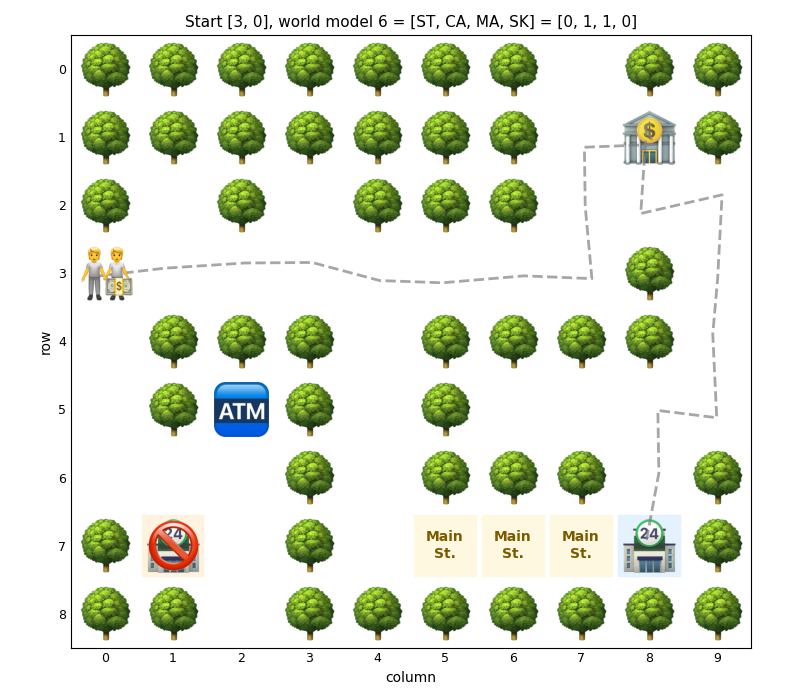

In [45]:
#----- your scenario: edit these five lines -----
scenario_start = [3, 0]  #where Alice and Bob begin, as [row, col]
ST = 0  #1 if Main Street is closed for a parade
CA = 1  #1 if Alice needs to collect cash before shopping
MA = 1  #1 if west mart is closed for renovations
SK = 0  #1 if the bank workers are on strike
#------------------------------------------------

#check that the scenario makes sense
for name, value in [("ST", ST), ("CA", CA), ("MA", MA), ("SK", SK)]:
    assert value in (0, 1), f"{name} must be 0 or 1, not {value}"
start_row, start_col = scenario_start
assert 0 <= start_row < n_rows and 0 <= start_col < n_cols, \
    f"scenario_start must be inside the map: rows 0 to {n_rows - 1}, columns 0 to {n_cols - 1}"
start_tile = worldmap[start_row, start_col]
assert start_tile != 1, f"{scenario_start} is covered in trees; pick another square"
assert not (start_tile == 6 and ST == 1), f"{scenario_start} is on Main Street, which is closed; pick another square"

#what participants were told about the day: every condition in effect, plus whether Alice has cash
condition_text = {
    "ST": "Main Street is closed for a parade today.",
    "CA": ["Alice already has cash on her.", "Alice needs to get cash from either the bank or the ATM."],
    "MA": "West-Mart is closed for renovations today.",
    "SK": "The bank workers are on strike today.",
}
print("What participants were told:")
print(f"  - {condition_text['CA'][CA]}")
for name, value in [("ST", ST), ("MA", MA), ("SK", SK)]:
    if value:
        print(f"  - {condition_text[name]}")
print()

#Alice's route: from the start, take the action with the highest Q-value until she reaches her goal
true_model = model_id(ST, CA, MA, SK)
s = start_row * n_cols + start_col
m = true_model
path_states = [s]
path_actions = []
while grid["goal_reached"][s, m] < 0.5 and len(path_actions) < plan_steps:
    a = int(jnp.argmax(grid["Q"][s, m]))
    next_s = int(grid["state_transitions"][s, a, m])
    next_m = int(grid["model_transitions"][m, s, a])
    path_actions.append(a)
    path_states.append(next_s)
    s, m = next_s, next_m

#describe the route in words
if grid["goal_reached"][s, m] > 0.5:
    shop = "west mart" if s == landmarks["WM"] else "east mart"
    print(f"Alice reaches {shop} in {len(path_actions)} steps:")
else:
    print(f"Alice doesn't reach a mart within {plan_steps} steps. Her first moves:")
for step, a in enumerate(path_actions, start=1):
    row, col = divmod(path_states[step - 1], n_cols)
    print(f"  {step:2d}. {action_names[a]:12s} from [{row}, {col}]")

#draw the scenario as participants saw it, with row and column numbers to help pick squares
fig, ax = plt.subplots(figsize=(8, 7))
draw_town(ax, conditions=(ST, CA, MA, SK), agent=scenario_start, path=path_states)
ax.set_xticks(range(n_cols))
ax.set_yticks(range(n_rows))
ax.tick_params(length=0, labelsize=9)
ax.set_xlabel("column")
ax.set_ylabel("row")
ax.set_title(f"Start {scenario_start}, world model {true_model} = [ST, CA, MA, SK] = {[ST, CA, MA, SK]}",
             fontsize=11)
plt.tight_layout()
plt.show()

## Watch Bob think, step by step

The next cell replays the scenario you defined above, one step at a time, and shows what Bob believes at each point. Run the scenario cell first. Then, whenever you change the scenario, run both cells again.

**How to use it.**

- **Click a grey dot** on Alice's route to move Alice and Bob to that step. The solid black line shows the part of the route Bob has already watched.
- A square that Alice visits twice, such as the bank or ATM where she stops to collect cash, holds two steps. Click it again to switch between them.
- You can also click the figure once and then use the **left and right arrow keys** to step backward and forward.

**What the two bar plots show.**

- **Top: Bob's guess about Alice's next move.** Bob doesn't know the world model, so he mixes his predictions from `bob_guesses_move` across all 16 world models, weighting each by how much he believes in it. The orange bar is the move Alice actually makes next.
- **Bottom: Bob's guess about the world model.** These are his beliefs over the 16 world models. Each label lists the four conditions in the order `[ST CA MA SK]`, so `0110` means Alice needs cash and west mart is closed. The orange bar is the world model Alice is really in.

**How Bob updates his beliefs.** Bob starts from his prior: 0.373 on an ordinary day and 0.042 on each of the other world models. After each move he watches, he does three things:

1. He multiplies his belief in each world model by how likely that move was under it. This is the same Bayes' rule as `bob_guesses_model`, applied once per move. So after an ordinary first move, the bottom plot matches the `bob_guesses_model` table above.
2. He rules out any world model in which the move was impossible. For example, if Alice walks along Main Street, it can't be closed. `bob_guesses_model` doesn't do this, because it only looks at which move Alice chose, not where she ended up.
3. When Alice collects cash, CA switches from 1 to 0, so his beliefs move to the matching world models with cash in hand.

**Things to look for:**

- Which moves change Bob's beliefs the most, and which change nothing? A move that every world model predicts equally well tells Bob nothing.
- Does Bob ever become sure of the true world model? If two world models predict the same route, such as when Alice never goes near Main Street, he can't tell them apart.
- At which steps does Bob's guess about the next move put the orange bar low? Those are the moments when Alice surprises him, and when he might ask "why?".

This cell needs the `ipympl` package to make the figure respond to clicks. If clicking does nothing, install it with `pip install ipympl`, restart the kernel, and run the notebook again. Running this cell also switches the notebook's plots to interactive mode; to switch back, run `%matplotlib inline`.

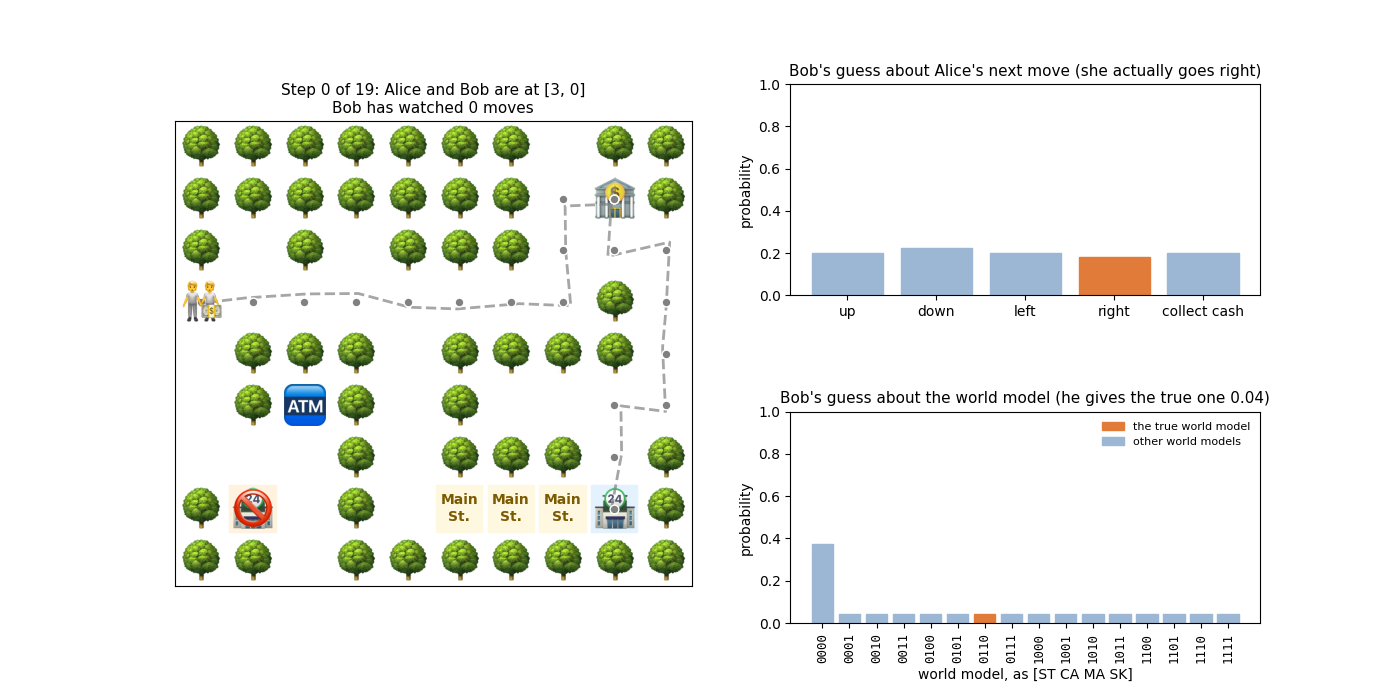

In [46]:
%matplotlib widget
#an interactive view of the scenario from the previous cell: click on Alice's route to move Alice and Bob

#----- Bob's beliefs at every step of the route -----
#Bob keeps one hypothesis for each world model Alice might have started in. After each move he watches:
#  1. he weighs each hypothesis by how likely that move was under it (the move_probs from bob_guesses_move),
#  2. he rules out any hypothesis under which the move would have taken Alice somewhere else,
#  3. he updates the world model each hypothesis is now in (collecting cash switches CA from 1 to 0).
move_probs_np = np.array(grid["move_probs"])
n_moves = len(path_actions)
weights = np.where(np.arange(16) == 0, 1.0, prior)  #Bob's prior over the world model Alice started in
current = np.arange(16)  #the world model each hypothesis is in now
true_now = true_model  #the world model Alice is really in now
beliefs = []  #beliefs[k][m]: Bob's belief that the world is now in model m, after watching k moves
true_models = []  #true_models[k]: the world model Alice is really in after k moves
for k in range(n_moves + 1):
    belief = np.zeros(16)
    np.add.at(belief, current, weights)
    beliefs.append(belief / belief.sum())
    true_models.append(true_now)
    if k < n_moves:
        s, a, s_next = path_states[k], path_actions[k], path_states[k + 1]
        weights = weights * move_probs_np[s, current, a]
        weights = weights * (state_transitions[s, a, current] == s_next)
        current = model_transitions[current, s, a]
        true_now = int(model_transitions[true_now, s, a])

#Bob's prediction of Alice's next move: his move predictions under each world model, weighted by his beliefs
next_move_probs = [beliefs[k] @ move_probs_np[path_states[k]] for k in range(n_moves + 1)]

#----- the figure: the map on the left, Bob's two guesses on the right -----
fig = plt.figure(figsize=(14, 7))
fig.canvas.header_visible = False
layout = fig.add_gridspec(2, 2, width_ratios=[1.1, 1], hspace=0.55)
ax_map = fig.add_subplot(layout[:, 0])
ax_move = fig.add_subplot(layout[0, 1])
ax_model = fig.add_subplot(layout[1, 1])

#the town with Alice's whole route, a dot on each square of the route to click, and the part Bob has watched
draw_town(ax_map, conditions=(ST, CA, MA, SK), path=path_states)
ax_map.set_autoscale_on(False)
route_rows = np.array([s // n_cols for s in path_states])
route_cols = np.array([s % n_cols for s in path_states])
ax_map.scatter(route_cols, route_rows, s=40, color="gray", edgecolor="white", zorder=6.5)
watched_line, = ax_map.plot([], [], "-", color="black", linewidth=3, alpha=0.8, zorder=6.6)
agent_image = ax_map.imshow(emoji["agent"], extent=(0, 1, 1, 0), zorder=7)
cash_image = ax_map.imshow(emoji["cash"], extent=(0, 1, 1, 0), zorder=8)

#Bob's guess about Alice's next move
move_bars = ax_move.bar(range(5), np.zeros(5), color="#9bb7d4")
ax_move.set_xticks(range(5))
ax_move.set_xticklabels(action_names)
ax_move.set_ylim(0, 1)
ax_move.set_ylabel("probability")

#Bob's guess about the world model
model_bars = ax_model.bar(range(16), np.zeros(16), color="#9bb7d4")
ax_model.set_xticks(range(16))
ax_model.set_xticklabels(["".join(str(int(v)) for v in condition_models_np[m]) for m in range(16)],
                         rotation=90, fontsize=9, family="monospace")
ax_model.set_xlabel("world model, as [ST CA MA SK]")
ax_model.set_ylim(0, 1)
ax_model.set_ylabel("probability")
ax_model.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#e07b39"), plt.Rectangle((0, 0), 1, 1, color="#9bb7d4")],
                labels=["the true world model", "other world models"], fontsize=8, loc="upper right", frameon=False)

step = 0

def show_step(k):
    """Move Alice and Bob to step k of the route and redraw Bob's guesses."""
    global step
    step = k
    row, col = route_rows[k], route_cols[k]
    agent_image.set_extent((col - 0.4, col + 0.4, row + 0.4, row - 0.4))
    cash_image.set_extent((col, col + 0.4, row + 0.4, row))
    cash_image.set_visible(bool(condition_models_np[true_models[k], 1]))  #Alice still needs cash
    watched_line.set_data(route_cols[:k + 1], route_rows[:k + 1])
    ax_map.set_title(f"Step {k} of {n_moves}: Alice and Bob are at [{row}, {col}]\n"
                     f"Bob has watched {k} move{'s' if k != 1 else ''}", fontsize=11)

    #next move: highlight the move Alice actually makes next
    for a, bar in enumerate(move_bars):
        bar.set_height(next_move_probs[k][a])
        bar.set_color("#e07b39" if k < n_moves and a == path_actions[k] else "#9bb7d4")
    if k < n_moves:
        ax_move.set_title(f"Bob's guess about Alice's next move (she actually goes {action_names[path_actions[k]]})",
                          fontsize=11)
    else:
        ax_move.set_title("Bob's guess about Alice's next move (she has reached the mart)", fontsize=11)

    #world model: highlight the world model Alice is really in now
    for m, bar in enumerate(model_bars):
        bar.set_height(beliefs[k][m])
        bar.set_color("#e07b39" if m == true_models[k] else "#9bb7d4")
    ax_model.set_title(f"Bob's guess about the world model (he gives the true one {beliefs[k][true_models[k]]:.2f})",
                       fontsize=11)
    fig.canvas.draw_idle()

def on_click(event):
    """Jump to the step of the route nearest the click; clicking a square again steps through its visits."""
    if event.inaxes is not ax_map or event.xdata is None:
        return
    distances = np.hypot(route_cols - event.xdata, route_rows - event.ydata)
    if distances.min() > 0.6:
        return
    visits = np.flatnonzero(distances == distances.min())
    later = visits[visits > step]
    show_step(int(later[0]) if step in visits and len(later) else int(visits[0]))

def on_key(event):
    """Step forward or back along the route with the arrow keys."""
    if event.key == "right":
        show_step(min(step + 1, n_moves))
    elif event.key == "left":
        show_step(max(step - 1, 0))

fig.canvas.mpl_connect("button_press_event", on_click)
fig.canvas.mpl_connect("key_press_event", on_key)
show_step(0)
plt.show()